In [59]:
#Get stats for plans
import json
import pandas as pd
import matplotlib.pyplot as plt
import folium
from IPython.display import display
import geopandas as gpd
import numpy as np

from matplotlib.ticker import ScalarFormatter

### Descriptive Stats about Documents (Extracted text, etc)

# of Documents: 612
                 0
count   612.000000
mean    122.063725
std     132.397053
min       2.000000
25%      42.750000
50%      84.000000
75%     148.000000
max    1095.000000


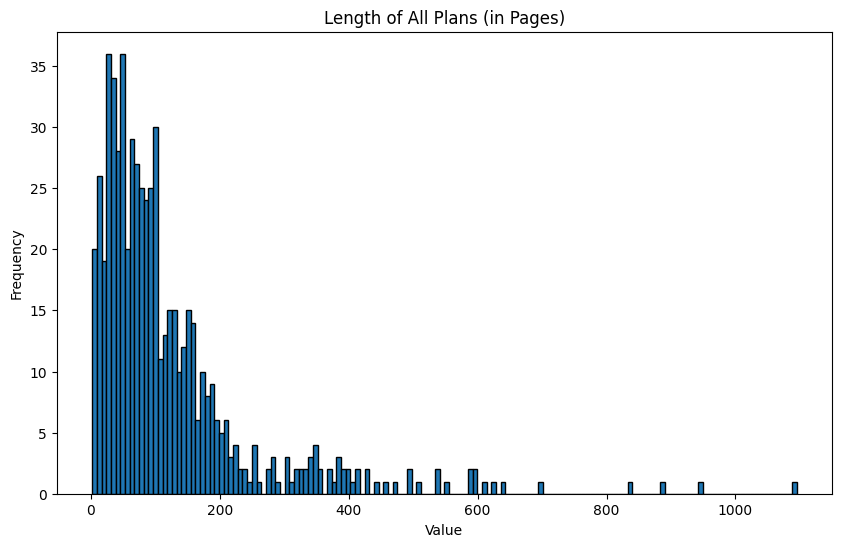

In [7]:
##Stats about Documents
with open('corpus/all_text.json', 'r', encoding='utf-8') as file:
        all_text = json.load(file)
        file.close()

##1. # of Docs 
print(f"# of Documents: {len(all_text.keys())}")

##2. Length of documents in pages (later: tokens, mean anything in different languages?)
doc_length = pd.DataFrame([len(all_text[doc]) for doc in all_text])
print(doc_length.describe())

#3. Histogram with pages
# Function to plot histogram
def plot_histogram(numbers, bins=150, title="Length of All Plans (in Pages)", xlabel="Value", ylabel="Frequency"):
    plt.figure(figsize=(10, 6))
    plt.hist(numbers, bins=bins, edgecolor='black')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    
    # Disable scientific notation on x-axis
    plt.gca().xaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    plt.gca().ticklabel_format(style='plain', axis='x')
    # plt.grid(True)
    plt.show()

plot_histogram(doc_length)

### Descriptive Stats about Plans with Metadata (Region, Year, etc)

In [9]:
### Get latest list 
documents = pd.read_csv('data/Data - Master Document List10.csv')

#Get only downloaded and relevant plans ##TODO: UPDATE
downloaded_docs = documents[documents['Document Status'] == 'Downloaded']
# downloaded_docs.loc['Plan Year'] = downloaded_docs['Plan Year'].astype(int)
print(f"# of Downloaded Documents: {len(downloaded_docs)}")
plans = downloaded_docs[downloaded_docs['Relevance Filter'] == 1]
plans['Plan Year'] = plans['Plan Year'].astype(int)
print(f"# of Relevant Plans: {len(plans)}")

##1. # of Languages of Relevant Documents
print(f"# of Languages: {len(plans['Document Language'].unique())}")

##2. Update Years graph - DONE
##2. Update Plan Types graph - DONE
##3. Per city stat 
    ## Cities with docs, with none, with some - DONE
    # How many cities have more than 1 doc? - DONE
    ## For cities with more than 1 doc, what are the types? - DONEISH
##3. Update global map
##4. By Region
    ## # of documents from target cities
    #types of documents
    #length of document
## Update global map to reflect
    ## of documents per city (bigger circle? opacity?)
    ## population? (bigger circle? opacity?)

plans

# of Downloaded Documents: 734
# of Relevant Documents: 612
# of Languages: 27


/var/folders/h1/_zymb6k15855dxzmpdj7099w0000gp/T/ipykernel_1188/2819018312.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plans['Plan Year'] = plans['Plan Year'].astype(int)


,,Region,ISO_Code,Country,City,City Code,Plan Name,Plan Name (Englishtranslation),Plan Type,Plan Year,...,Document Language,Document Name,Document Link,Document Translation,Attachment/ link and name of plan,Notes,Dataset Source,Organization Name,Municipal Link,PR
3,3.0,Latin America and the Caribbean,ARG,Argentina,Buenos Aires,20058,Plan de Acción Climática 2050,Climate Action Plan 2050,General Climate Plan,2020,...,Spanish,20058-2020-pac_2050_buenos_aires_0.pdf,https://drive.google.com/file/d/1anxfRWwHxiN9t...,NaN,Pac_2050_buenos_aires.pdf,NaN,CDP 2023 Climate Action Plans,City of Buenos Aires,NaN,NaN
4,5.0,Latin America and the Caribbean,ARG,Argentina,Buenos Aires,20058,Plan de Accion Contra el Cambio Climatico - Ca...,Action Plan Against Climate Change - Chapter 6...,Adaptation or Climate Resilience Plan,2010,...,Spanish,20058-2010-cap6_pacc_ba3030.pdf,https://drive.google.com/file/d/1tkO-C0D6fGToO...,NaN,NaN,NaN,"Araos et al., “Climate Change Adaptation Plann...",NaN,NaN,NaN
5,6.0,Latin America and the Caribbean,ARG,Argentina,Buenos Aires,20058,Buenos Aires Resiliente,Resilient Buenos Aires,Resilience/Sustainability,2018,...,Spanish,20058-2018-Buenos-Aires-Estrategia-de-Resilien...,https://drive.google.com/file/d/1on-jsNDsJpGnV...,NaN,NaN,Original link is broken,"Olazabal et al., ""A cross-scale worldwide anal...",Gobierno de la Ciudad de Buenos Aires,https://www.buenosaires.gob.ar/,NaN
6,NaN,Latin America and the Caribbean,ARG,Argentina,Buenos Aires,20058,PACC - Plan de Acción frente el cambio climáti...,PACC - Action Plan against climate change 2020,General Climate Plan,2015,...,Spanish,20058-2015-pacc_2020.pdf,https://drive.google.com/file/d/1sdNejL82i-5Mu...,NaN,NaN,NaN,"Olazabal et al., ""A cross-scale worldwide anal...",Gobierno de la Ciudad de Buenos Aires,https://www.buenosaires.gob.ar/,NaN
7,7.0,Latin America and the Caribbean,ARG,Argentina,Córdoba,20059,Estrategias de desarrollo integral para el are...,Comprehensive development strategies for the m...,Resilience/Sustainability,2020,...,Spanish,20059-2020-CDS-Estrategias-de-desarrollo-integ...,https://drive.google.com/file/d/1SAHEykmZHN3b_...,NaN,NaN,NaN,Manual search,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
986,NaN,Asia,VNM,Viet Nam,Da Nang,22455,Kế hoạch hành động về khí hậu của Đà Nẵng,Da Nang's climate action plan,General Climate Plan,2023,...,Vietnamese,22455-2023-Da+Nang+Climate+Action+Plan_2nd+Edi...,https://drive.google.com/file/d/1HoVM_7XY4qH6S...,NaN,NaN,NaN,Automated Google Search,NaN,NaN,NaN
987,NaN,Asia,VNM,Viet Nam,Da Nang,22455,Resilient Da Nang,Resilient Da Nang,Resilience/Sustainability,2016,...,English,22455-2016-Da-Nang-Resilience-Strategy-English...,https://drive.google.com/file/d/1K91eOtMJ17DaZ...,NaN,NaN,NaN,Manual Google Search,NaN,NaN,NaN
988,842.0,Asia,VNM,Viet Nam,Hà Noi,22457,Hà Nội 2021 Kế hoạch hành động ứng phó với biế...,Hanoi 2021 Action plan to respond to climate c...,General Climate Plan,2021,...,Vietnamese,22457-2021-quyet-dinh-5384-qd-ubnd-uy-ban-nhan...,https://drive.google.com/file/d/1mt6R0lSs8u6ko...,NaN,NaN,OCR needed,NaN,NaN,NaN,NaN
990,846.0,Asia,VNM,Viet Nam,Hai Phòng,22456,KẾ HOẠCH HÀNH ĐỘNG ỨNG PHÓ VỚI BIẾN ĐỔI KHÍ HẬ...,ACTION PLAN TO RESPOND TO CLIMATE CHANGE OF HA...,General Climate Plan,2020,...,Vietnamese,22456-2020-ccap hai phong.pdf,https://drive.google.com/file/d/1KoSs8eamM5QSB...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


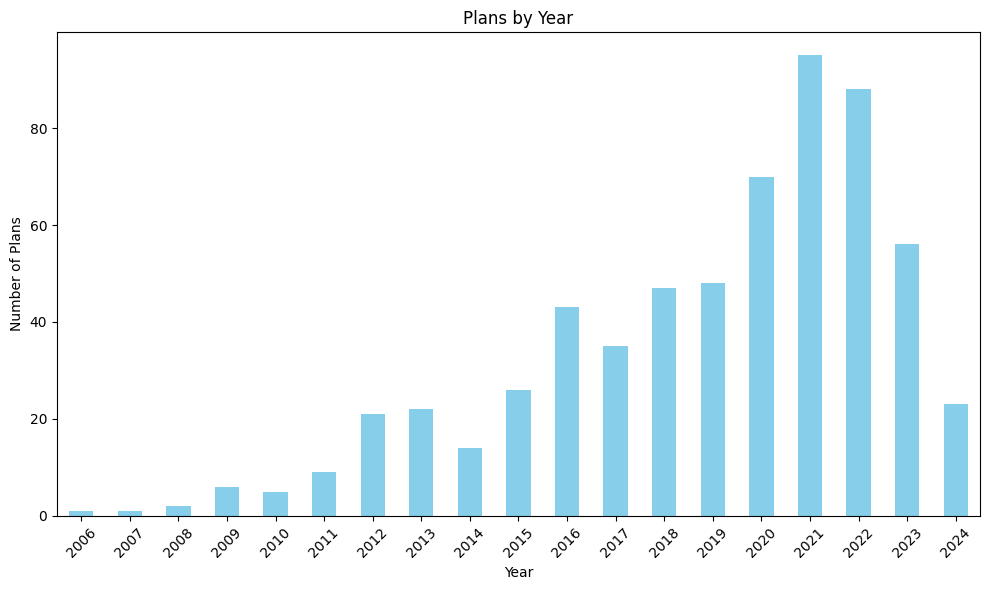

In [31]:
#Bar Chart for Plans
year_counts = plans['Plan Year'].value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
year_counts.plot(kind='bar', color='skyblue')
plt.title('Plans by Year')
plt.xlabel('Year')
plt.ylabel('Number of Plans')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

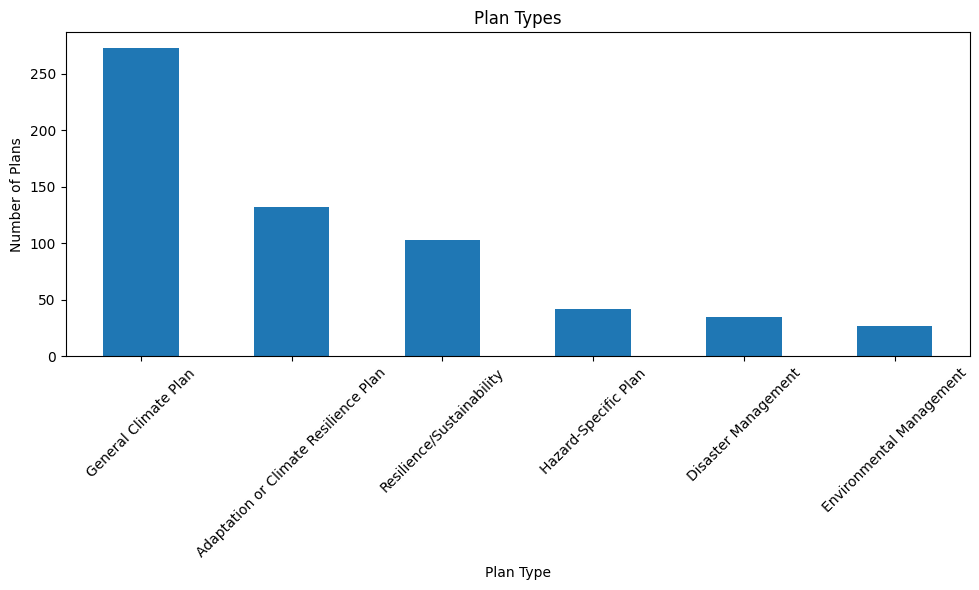

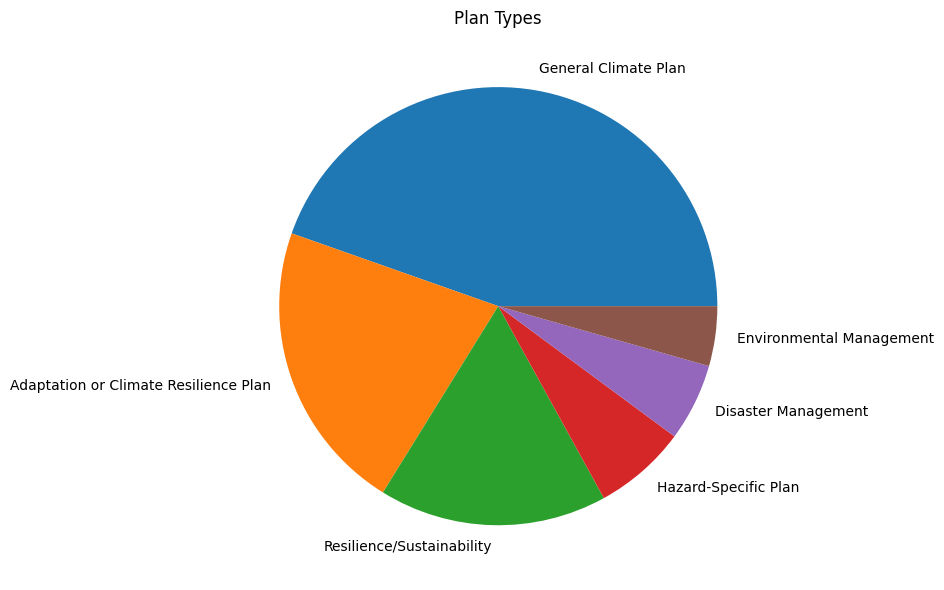

In [32]:
#Bar Chart for Type of Plans
plan_types = plans['Plan Type'].value_counts().sort_values(ascending=False)

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plan_types.plot(kind='bar')
plt.title('Plan Types')
plt.ylabel('Number of Plans')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plan_types.plot(kind='pie')
plt.title('Plan Types')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Calculate stats per city

In [40]:
###Calculate # of cities with plans, with some evidence, with none 
documents_by_city = documents.groupby('City Code')

# Function to determine the 'Plan Status' for each city group
def get_plan_status(group):
    relevant_docs = group[group['Relevance Filter'] == 1]
    if 'Downloaded' in relevant_docs['Document Status'].values:
        return 'Found'
    elif 'Searched, Not Found' in group['Document Status'].values:
        return 'None'
    else:
        return 'Some'

# Group by 'City Code' and apply the function
plan_status_by_city = documents_by_city.apply(get_plan_status).reset_index()

# Rename the columns appropriately
plan_status_by_city.columns = ['City Code', 'Plan Status']
print(plan_status_by_city['Plan Status'].value_counts().sum())
print(plan_status_by_city['Plan Status'].value_counts()) ##Double-check this, print lists of cities, look at previous method

548
Plan Status
Found    322
None     183
Some      43
Name: count, dtype: int64


/var/folders/h1/_zymb6k15855dxzmpdj7099w0000gp/T/ipykernel_1188/3872143110.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  plan_status_by_city = documents_by_city.apply(get_plan_status).reset_index()


Plan Type
1    166
2     85
3     35
4     19
5     11
6      4
7      1
9      1
Name: count, dtype: int64
# of Cities with > 1 plan: 156
% of Cities with > plan: 48.4472049689441


<Axes: title={'center': 'Distribution of Cities with Multiple Plans'}, xlabel='# of Plans', ylabel='# of Cities'>

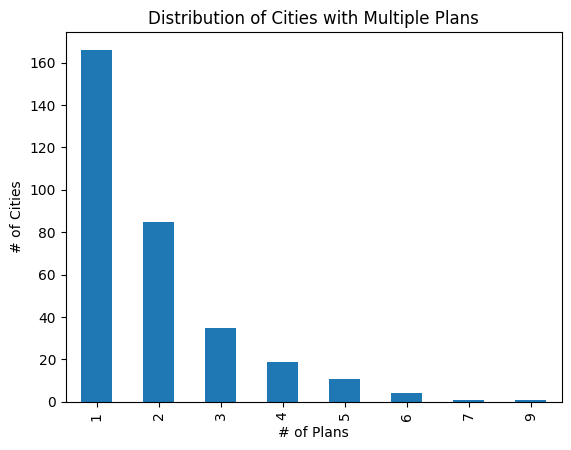

In [63]:
## Calculate # of plans by City

#Combine plans by city code
plans_by_city = plans.groupby('City Code')

#calculate # of plans per city
plans_by_city_count = plans_by_city['Plan Type'].count()
total_plans_by_city_count= plans_by_city_count.value_counts()
# total_plans_by_city_count = total_plans_by_city_count.astype(int)
print(total_plans_by_city_count)
##Which cities have 6, 7, 9 plans?

#Get the cities with multiple plans
total_multi_plan_cities = total_plans_by_city_count[total_plans_by_city_count.index > 1].sum()
print("# of Cities with > 1 plan:", total_multi_plan_cities)
print("% of Cities with > plan:", (total_multi_plan_cities/total_plans_by_city_count.sum())*100)

#Plot it
total_plans_by_city_count.plot(kind='bar', title='Distribution of Cities with Multiple Plans',
                               xlabel='# of Plans', ylabel='# of Cities')

City Code
20058        4
20107        4
20142        3
20144        2
20152        2
            ..
206168       2
206170       4
206171       9
206459       3
895000389    3
Name: Plan Type, Length: 156, dtype: int64
                               Plan Type  Count
0                   General Climate Plan    212
1  Adaptation or Climate Resilience Plan    111
2              Resilience/Sustainability     82
3                   Hazard-Specific Plan     32
4               Environmental Management      6
5                    Disaster Management      3


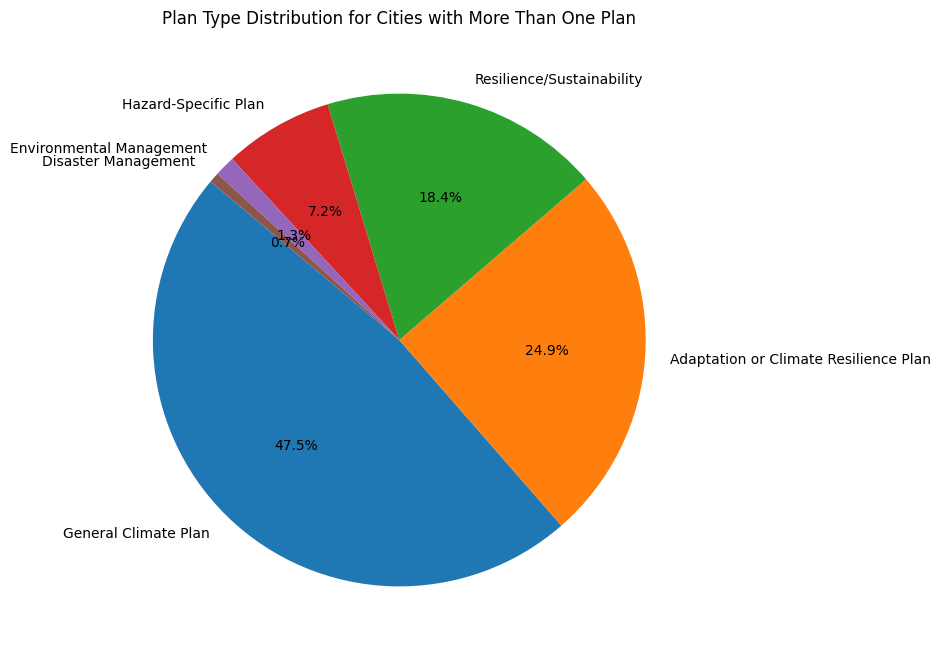

Region
Asia                               219
Northern America                   121
Europe                             120
Latin America and the Caribbean     87
Africa                              44
Oceania                             21
Name: count, dtype: int64
Region
Asia                               120
Europe                             110
Northern America                   106
Latin America and the Caribbean     55
Africa                              35
Oceania                             20
Name: count, dtype: int64
Region
Africa                             79.545455
Asia                               54.794521
Europe                             91.666667
Latin America and the Caribbean    63.218391
Northern America                   87.603306
Oceania                            95.238095
Name: count, dtype: float64


In [73]:
##Cities with multiple plans
## Get cities with multiple plans
multi_plan_city_codes = plans_by_city_count[plans_by_city_count > 1]
print(multi_plan_city_codes)
multi_plan_cities = plans[plans['City Code'].isin(multi_plan_city_codes.index)]


# Step 2: Group by 'City Code' and 'Plan Type', and count occurrences
multi_plan_cities_plan_types = multi_plan_cities['Plan Type'].value_counts().reset_index()
multi_plan_cities_plan_types.columns = ['Plan Type', 'Count']
# Display the result
print(multi_plan_cities_plan_types)

# Step 3: Create a single pie chart for the aggregated data
plt.figure(figsize=(8, 8))
plt.pie(multi_plan_cities_plan_types['Count'], labels=multi_plan_cities_plan_types['Plan Type'], autopct='%1.1f%%', startangle=140)
plt.title('Plan Type Distribution for Cities with More Than One Plan')
plt.show()

# Get Region of multi plan cities
total_plans_cities_regions = plans['Region'].value_counts() 
multi_plan_cities_regions = multi_plan_cities['Region'].value_counts()
print(total_plans_cities_regions)
print(multi_plan_cities_regions)
print((multi_plan_cities_regions/total_plans_cities_regions)*100)

### Global Map

In [29]:
##Global Map with locations
city_list = pd.read_csv('output/1mill_pop_cities.csv')
global_plan_status = pd.merge(city_list, plan_status_by_city, on='City Code', how='left')
city_plan_count = plans_by_city.count()
# Create a folium map centered around the mean coordinates
map_center = [global_plan_status['Latitude'].mean(), global_plan_status['Longitude'].mean()]
my_map = folium.Map(location=map_center, zoom_start=4)

# Add markers for each data point
for index, row in global_plan_status.iterrows():
    if row['Plan Status'] == 'Found':
        marker_color = 'green'
    elif row['Plan Status'] == 'Some':
        marker_color = 'orange'
    else:
        marker_color = 'black'

    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=3,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=1,
        popup=folium.Popup(row['City'], parse_html=True)
    ).add_to(my_map)

# Display the map directly in the Jupyter Notebook
display(my_map)

# Save the map to an HTML file
# my_map.save('output/downloaded_city_plans_map.html')

### Stats by Region

In [ ]:
regions_df = pd.read_csv('data/iso_region_mapping.csv')
merged_df = pd.merge(regions_df, plans, left_on='alpha-3', right_on='ISO_Code')

### Other Code for Identifying Missing Docs, etc

In [12]:
#load documents to get list of missing cities
plans = pd.read_csv('data/Data - Master Document List8.csv')
regions_df = pd.read_csv('data/iso_region_mapping.csv')


merged_df.loc[merged_df['sub-region'] == 'Latin America and the Caribbean', 'region'] = 'Latin America and the Caribbean'
merged_df.loc[merged_df['sub-region'] == 'Northern America', 'region'] = 'Northern America'
print(merged_df.head(10))

merged_df.to_csv("output/plans_with_regions.csv")

          name alpha-2 alpha-3  country-code     iso_3166-2  \
0  Afghanistan      AF     AFG             4  ISO 3166-2:AF   
1      Albania      AL     ALB             8  ISO 3166-2:AL   
2      Algeria      DZ     DZA            12  ISO 3166-2:DZ   
3       Angola      AO     AGO            24  ISO 3166-2:AO   
4    Argentina      AR     ARG            32  ISO 3166-2:AR   
5    Argentina      AR     ARG            32  ISO 3166-2:AR   
6    Argentina      AR     ARG            32  ISO 3166-2:AR   
7    Argentina      AR     ARG            32  ISO 3166-2:AR   
8    Argentina      AR     ARG            32  ISO 3166-2:AR   
9    Argentina      AR     ARG            32  ISO 3166-2:AR   

                            region                       sub-region  \
0                             Asia                    Southern Asia   
1                           Europe                  Southern Europe   
2                           Africa                  Northern Africa   
3                     

In [19]:
#load documents to get list of missing cities
documents = pd.read_csv('data/Data - Master Document List9.csv')
# city_list = pd.read_csv('output/capital_and_1mill_pop_cities.csv')
city_list = pd.read_csv('output/1mill_pop_cities.csv')

#Get only relevant plans
plans = documents[documents['Relevance Filter'] == 1]

#Get stats about the # of documents and years for each city
# downloaded_plans = plans[(plans['Document Status'] == 'Downloaded') | ((plans['Document Status'].isna()) & (plans['Plan Link'].notna())) ]
downloaded_plans = plans[plans['Document Status'] == 'Downloaded']

# Number of Downloaded docs
downloaded_counts = downloaded_plans.groupby('City Code').size().reset_index()
downloaded_counts.rename(columns={0:'Downloaded Count'}, inplace=True)

# Merge the datasets based on common columns 'City Code'
city_doc_status = pd.merge(city_list, downloaded_counts, on='City Code', how='left')
city_doc_status['Downloaded Count'] = city_doc_status['Downloaded Count'].fillna(0)

searched_not_found = plans[plans['Document Status'] == 'Searched, Not Found'] 

# Find cities with 'Searched, Not Found' status
searched_not_found_cities = searched_not_found['City Code'].unique()

# Identify cities where the download count is 0 or where the city code has 'Searched, Not Found'
missing_cities = city_doc_status[(city_doc_status['Downloaded Count'] == 0)] 
missing_cities = missing_cities[(city_doc_status['ISO_Code'] != 'CHN') & (~city_doc_status['City Code'].isin(searched_not_found_cities))]


# missing_cities = city_doc_status[city_doc_status['Downloaded Count'] == 0]
missing_cities

#write to file to do some searches!
# missing_cities.to_csv('output/missing_cities2.csv')


/var/folders/h1/_zymb6k15855dxzmpdj7099w0000gp/T/ipykernel_49878/1606366551.py:28: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  missing_cities = missing_cities[(city_doc_status['ISO_Code'] != 'CHN') & (~city_doc_status['City Code'].isin(searched_not_found_cities))]


,Unnamed: 0,Country,City,City Code,Latitude,Longitude,Population,ISO_Code,Language Code,Other Languages,Language,Downloaded Count
0,1,Afghanistan,Kabul,20002,34.528887,69.172460,4011.770,AFG,fa,"['ps', 'uz-AF', 'tk']",Persian,0.0
1,8,Algeria,El Djazaïr (Algiers),20006,36.752500,3.041970,2693.542,DZA,ar,[],Arabic,0.0
2,18,Angola,Luanda,20049,-8.836820,13.234320,7774.200,AGO,pt,[],Portuguese,0.0
14,52,Azerbaijan,Baku,20053,40.377670,49.892010,2285.729,AZE,az,"['ru', 'hy']",Azerbaijani,0.0
15,58,Bangladesh,Chittagong,20115,22.333060,91.836390,4815.545,BGD,bn,['en'],Bengali,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
538,1831,Venezuela (Bolivarian Republic of),Maracay,23227,10.246940,-67.595830,1177.540,VEN,es,[],Spanish,0.0
539,1835,Venezuela (Bolivarian Republic of),Valencia,23233,10.162020,-68.007650,1860.329,VEN,es,[],Spanish,0.0
545,1852,Yemen,Sana'a',23239,15.353115,44.207820,2779.317,YEM,ar,[],Arabic,0.0
546,1855,Zambia,Lusaka,23277,-15.413374,28.277148,2523.844,ZMB,en,"['bem', 'loz', 'lun', 'lue', 'ny', 'toi']",English,0.0


In [36]:
#Get stats about the # of documents and years for each city
downloaded_plans = plans[plans['Document Status'] == 'Downloaded']
# downloaded_plans = plans[(plans['Document Status'] == 'Downloaded') | ((plans['Document Status'].isna()) & (plans['Plan Link'].notna())) ]
print(f'# of Documents: {downloaded_plans.shape[0]}')

# Number of Downloaded docs
downloaded_counts = downloaded_plans.groupby('City Code').size().reset_index()
downloaded_counts.rename(columns={0:'Downloaded Count'}, inplace=True)
print(f'# of Cities with Plans: {downloaded_counts.shape[0]}')

#Number of Cities with no evidence of plans
no_plans = documents[documents['Document Status'] == 'Searched, Not Found']
none_counts = no_plans.groupby('City Code').size().reset_index()
none_counts.rename(columns={0:'Downloaded Count'}, inplace=True)
print(f'# of Cities with no Evidence of Plans: {none_counts.shape[0]}')

#Number of Cities with some evidence of plans
some_plans = documents[(documents['Document Status'] == 'Broken Link') | (plans['Document Status'] == 'PDF Name Not Found')]
some_counts = some_plans.groupby('City Code').size().reset_index()
some_counts.rename(columns={0:'Downloaded Count'}, inplace=True)
print(f'# of Cities with Some Evidence of Plans: {some_counts.shape[0]}')

# # year range
downloaded_years = downloaded_plans.groupby('City Code')['Plan Year'].apply(list).reset_index()
downloaded_years.rename(columns={'Plan Year':'Plan Years'}, inplace=True)
print(downloaded_years)

# Merge the datasets based on common columns 'City Code'
city_doc_status = pd.merge(city_list, downloaded_counts, on='City Code', how='left')
city_doc_status = city_doc_status.merge(downloaded_years, on='City Code', how='left')
city_doc_status['Downloaded Count'] = city_doc_status['Downloaded Count'].fillna(0)

#
def get_search_status(city):
    if city in downloaded_counts['City Code'].values:
        return 1
    # elif city in some_counts['City Code'].values:
    #     return -1
    elif city in none_counts['City Code'].values:
        return 0
    else: return -1
                        

##TODO: create 'Search Status' col, if in downloaded docs, then 1, or 0 for
city_doc_status['Search Status'] = city_doc_status['City Code'].apply(get_search_status)

city_doc_status

# of Documents: 614
# of Cities with Plans: 326
# of Cities with no Evidence of Plans: 183
# of Cities with Some Evidence of Plans: 45
     City Code                        Plan Years
0        20058  [2020.0, 2010.0, 2018.0, 2015.0]
1        20059                          [2020.0]
2        20068                          [2020.0]
3        20075                          [2018.0]
4        20107  [2009.0, 2022.0, 2022.0, 2022.0]
..         ...                               ...
321  895000149                          [2022.0]
322  895000150                          [2012.0]
323  895000388                          [2018.0]
324  895000389          [2023.0, 2016.0, 2021.0]
325  895000391                          [2015.0]

[326 rows x 2 columns]


,Unnamed: 0,Country,City,City Code,Latitude,Longitude,Population,ISO_Code,Language Code,Other Languages,Language,Downloaded Count,Plan Years,Search Status
0,1,Afghanistan,Kabul,20002,34.528887,69.172460,4011.770,AFG,fa,"['ps', 'uz-AF', 'tk']",Persian,0.0,NaN,0
1,8,Algeria,El Djazaïr (Algiers),20006,36.752500,3.041970,2693.542,DZA,ar,[],Arabic,0.0,NaN,0
2,18,Angola,Luanda,20049,-8.836820,13.234320,7774.200,AGO,pt,[],Portuguese,0.0,NaN,0
3,23,Argentina,Buenos Aires,20058,-34.605083,-58.400368,14966.530,ARG,es,"['en', 'it', 'de', 'fr', 'gn']",Spanish,4.0,"[2020.0, 2010.0, 2018.0, 2015.0]",1
4,24,Argentina,Córdoba,20059,-31.413500,-64.181050,1548.176,ARG,es,"['en', 'it', 'de', 'fr', 'gn']",Spanish,1.0,[2020.0],1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543,1840,Viet Nam,Hai Phòng,22456,20.864810,106.683450,1219.352,VNM,vi,"['en', 'fr', 'zh', 'km']",Vietnamese,1.0,[2020.0],1
544,1844,Viet Nam,Thành Pho Ho Chí Minh (Ho Chi Minh City),22458,10.750000,106.666670,8145.361,VNM,vi,"['en', 'fr', 'zh', 'km']",Vietnamese,1.0,[2021.0],1
545,1852,Yemen,Sana'a',23239,15.353115,44.207820,2779.317,YEM,ar,[],Arabic,0.0,NaN,0
546,1855,Zambia,Lusaka,23277,-15.413374,28.277148,2523.844,ZMB,en,"['bem', 'loz', 'lun', 'lue', 'ny', 'toi']",English,0.0,NaN,0


In [26]:
#Stats based on regions
countries_df = pd.read_csv('data/iso_region_mapping.csv')

# Merge keyword counts with cities data
merged_df = pd.merge(countries_df, city_list, left_on='alpha-3', right_on='ISO_Code')
merged_df.loc[merged_df['sub-region'] == 'Latin America and the Caribbean', 'region'] = 'Latin America and the Caribbean'
merged_df.loc[merged_df['sub-region'] == 'Northern America', 'region'] = 'Northern America'
print(merged_df.head(10))

# of cities in each region, then % of cities that have plans
cities_per_region = merged_df.groupby('region').size()
print(cities_per_region)

cities_with_plans = pd.merge(merged_df, city_doc_status, left_on='City Code', right_on='City Code')
cities_with_plans_per_region = cities_with_plans[cities_with_plans['Downloaded Count'] > 0].groupby('region').size() 
cities_with_plans_per_region

percentage_plans_per_region = (cities_with_plans_per_region/cities_per_region)*100
percentage_plans_per_region

          name alpha-2 alpha-3  country-code     iso_3166-2  \
0  Afghanistan      AF     AFG             4  ISO 3166-2:AF   
1      Algeria      DZ     DZA            12  ISO 3166-2:DZ   
2       Angola      AO     AGO            24  ISO 3166-2:AO   
3    Argentina      AR     ARG            32  ISO 3166-2:AR   
4    Argentina      AR     ARG            32  ISO 3166-2:AR   
5    Argentina      AR     ARG            32  ISO 3166-2:AR   
6    Argentina      AR     ARG            32  ISO 3166-2:AR   
7      Armenia      AM     ARM            51  ISO 3166-2:AM   
8    Australia      AU     AUS            36  ISO 3166-2:AU   
9    Australia      AU     AUS            36  ISO 3166-2:AU   

                            region                       sub-region  \
0                             Asia                    Southern Asia   
1                           Africa                  Northern Africa   
2                           Africa               Sub-Saharan Africa   
3  Latin America and t

region
Africa                              34.920635
Asia                                51.006711
Europe                              72.413793
Latin America and the Caribbean     75.000000
Northern America                    96.078431
Oceania                            100.000000
dtype: float64

/var/folders/h1/_zymb6k15855dxzmpdj7099w0000gp/T/ipykernel_3401/297848261.py:2: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


ValueError: aspect must be finite and positive 

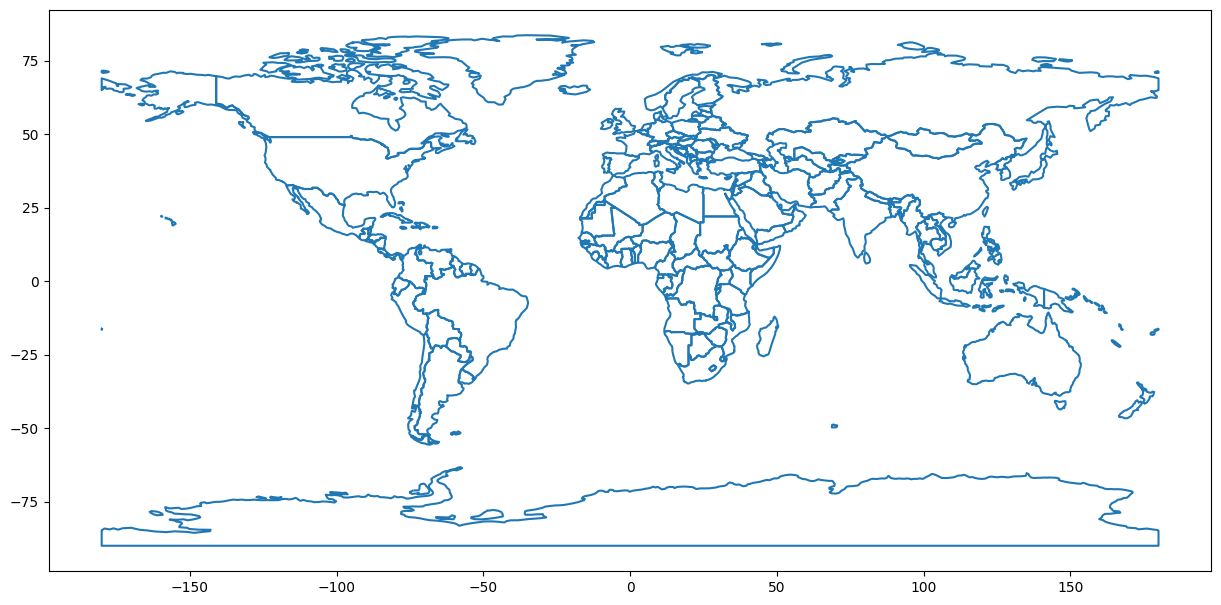

In [57]:
# Load the world map
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Map the sub-regions to the percentages
sub_region_map = {
    'Australia and New Zealand': 100.0,
    'Central Asia': float('nan'),
    'Eastern Asia': 68.21,
    'Eastern Europe': 30.77,
    'Latin America and the Caribbean': 65.63,
    'Melanesia': 40.0,
    'Micronesia': float('nan'),
    'Northern Africa': float('nan'),
    'Northern America': 94.44,
    'Northern Europe': 77.78,
    'Polynesia': 12.5,
    'South-eastern Asia': 64.71,
    'Southern Asia': 31.03,
    'Southern Europe': 85.71,
    'Sub-Saharan Africa': 24.36,
    'Western Asia': 37.84,
    'Western Europe': 78.26
}

# Add sub-region data to the world map
world['sub_region'] = world['continent']  # Dummy mapping, replace with actual sub-region data
world['percentage'] = world['sub_region'].map(sub_region_map)

# Plot the world map with color coding
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
world.boundary.plot(ax=ax)
world.dropna(subset=['percentage']).plot(column='percentage', ax=ax, legend=True,
                                         legend_kwds={'label': "Percentage of Cities with Plans",
                                                      'orientation': "horizontal"},
                                         cmap='coolwarm')
plt.title('World Map with Percentage of Cities with Plans by Sub-Region')
plt.show()


In [60]:
import seaborn as sns

# Heatmap
plt.figure(figsize=(12, 8))
heatmap_data = percentage_plans_per_region.T
sns.heatmap(heatmap_data, annot=True, cmap='coolwarm', cbar_kws={'label': 'Percentage'})
plt.title('Heatmap of Percentage of Cities with Plans by Sub-Region')
plt.tight_layout()
plt.show()

IndexError: Inconsistent shape between the condition and the input (got (17, 1) and (17,))

<Figure size 1200x800 with 0 Axes>

In [25]:
# Function to create pie chart for each region
def create_pie_chart(region, percentage, n_value):
    labels = [f'{region} ({n_value})', f'Other ({100 - percentage:.2f}%)']
    sizes = [percentage, 100 - percentage]
    colors = ['green', 'lightgrey']
    
    fig, ax = plt.subplots()
    ax.pie(sizes, colors=colors, autopct='%1.0f%%', startangle=140, textprops={'fontsize': 36})
    ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
    plt.title(f'{region} (Total Cities = {n_value})')
    plt.show()

# Generate pie charts
for index, value in percentage_plans_per_region.items():
    region = index
    percentage = value
    n_value = cities_per_region[region]  # Replace with actual n_value as needed
    create_pie_chart(region, percentage, n_value)

NameError: name 'percentage_plans_per_region' is not defined

In [4]:
#First print the full city list
# city_doc_status.to_csv('output/city_list_document_status.csv')

In [72]:
#Map for Downloaded Plan Locations

# Create a folium map centered around the mean coordinates
map_center = [city_doc_status['Latitude'].mean(), city_doc_status['Longitude'].mean()]
my_map = folium.Map(location=map_center, zoom_start=4)

# Add markers for each data point
for index, row in city_doc_status.iterrows():
    marker_color = 'green' if row['Downloaded Count'] != 0 else 'blue'
    folium.Marker(location=[row['Latitude'], row['Longitude']], popup=row['City'], icon=folium.Icon(color=marker_color, icon='fa-solid fa-circle')).add_to(my_map)

# Display the map directly in the Jupyter Notebook
display(my_map)

my_map.save('output/downloaded_city_plans_map.html')

In [34]:
city_doc_status
print(city_doc_status['Search Status'].value_counts())

Search Status
 1    325
 0    183
-2     24
-1     16
Name: count, dtype: int64


In [35]:


# Create a folium map centered around the mean coordinates
map_center = [city_doc_status['Latitude'].mean(), city_doc_status['Longitude'].mean()]
my_map = folium.Map(location=map_center, zoom_start=4)

# Add markers for each data point
for index, row in city_doc_status.iterrows():
    if row['Search Status'] == 1:
        marker_color = 'green'
    elif row['Search Status'] == -1:
        marker_color = 'orange'
    else:
        marker_color = 'black'

    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=3,
        color=marker_color,
        fill=True,
        fill_color=marker_color,
        fill_opacity=1,
        popup=folium.Popup(row['City'], parse_html=True)
    ).add_to(my_map)

# Display the map directly in the Jupyter Notebook
display(my_map)

# Save the map to an HTML file
my_map.save('output/downloaded_city_plans_map.html')


In [6]:
#Do something about missing plans
missing_cities = city_doc_status[city_doc_status['Search Status'] == -2]
missing_cities
missing_country_counts = missing_cities.groupby('Country').size().reset_index()
print(missing_country_counts.head())
missing_country_counts.rename(columns={0:'Count'}, inplace=True)
missing_country_counts.sort_values(by=['Count'], ascending=False, inplace=True)
# missing_country_counts.to_csv('output/missing_countries.csv')

missing_cities #TODO, list missing cities with populations over 1 million
print(len(missing_cities[missing_cities['Population'] > 1000]))

merged_df = pd.merge(countries_df, missing_cities, left_on='alpha-3', right_on='ISO_Code')
merged_df.loc[merged_df['sub-region'] == 'Latin America and the Caribbean', 'region'] = 'Latin America and the Caribbean'
merged_df.loc[merged_df['sub-region'] == 'Northern America', 'region'] = 'Northern America'
# print(merged_df.head(10))

# merged_df.to_csv('output/missing_cities_by_region.csv')

# of cities in each region, then % of cities that have plans
missing_cities_per_region = merged_df.groupby('region').size()
missing_cities_per_region

#write to file to do some searches!
# missing_cities.to_csv('output/missing_cities.csv')

                           Country  0
0                          Belarus  1
1                         Cambodia  1
2                            China  2
3  China, Taiwan Province of China  1
4  Dem. People's Republic of Korea  1
40


NameError: name 'countries_df' is not defined